# Importation des bibliothèques et du dataset

In [1]:
# Importation de différents modules pour l'analyse et la visualisation des données

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Test statistique

from scipy.stats import chi2_contingency
from scipy.stats import mannwhitneyu

In [2]:
# Test de plusieurs encodages possibles pour éviter les erreurs d'encodage

def read_file_multiple_encodings(file_path):
    """
    Try multiple common encodings until one succeeds.

    Args:
        file_path: Path to the file to read

    Returns:
        File content as string, or None if all encodings fail
    """
    common_encodings = ['utf-8', 'utf-8-sig', 'windows-1252', 'iso-8859-1', 'cp1252']

    for encoding in common_encodings:
        try:
            with open(file_path, 'r', encoding=encoding) as file:
                content = file.read()
                print(f"✓ Successfully read with {encoding}")
                return content
        except UnicodeDecodeError:
            print(f"Failed with {encoding}")
            continue

    print("All standard encodings failed")
    return None

# Example usage
content = read_file_multiple_encodings("Speed_dating_data.csv")
if content is None:
    print("Manual intervention required!")


Failed with utf-8
Failed with utf-8-sig
✓ Successfully read with windows-1252


In [3]:
# Importation du dataset en utilisant le bon encodage détecté

df = pd.read_csv("Speed_dating_data.csv", encoding="cp1252")
print(df.head())


   iid   id  gender  idg  condtn  wave  round  position  positin1  order  ...  \
0    1  1.0       0    1       1     1     10         7       NaN      4  ...   
1    1  1.0       0    1       1     1     10         7       NaN      3  ...   
2    1  1.0       0    1       1     1     10         7       NaN     10  ...   
3    1  1.0       0    1       1     1     10         7       NaN      5  ...   
4    1  1.0       0    1       1     1     10         7       NaN      7  ...   

   attr3_3  sinc3_3  intel3_3  fun3_3  amb3_3  attr5_3  sinc5_3  intel5_3  \
0      5.0      7.0       7.0     7.0     7.0      NaN      NaN       NaN   
1      5.0      7.0       7.0     7.0     7.0      NaN      NaN       NaN   
2      5.0      7.0       7.0     7.0     7.0      NaN      NaN       NaN   
3      5.0      7.0       7.0     7.0     7.0      NaN      NaN       NaN   
4      5.0      7.0       7.0     7.0     7.0      NaN      NaN       NaN   

   fun5_3  amb5_3  
0     NaN     NaN  
1     NaN 

# EDA

## Analyse de la structure du dataset

In [4]:
# Affichage de la forme du dataset pour comprendre sa structure

df.shape
print(f"Le dataset contient {df.shape[0]} lignes et {df.shape[1]} colonnes.")

# Affichage des doublons

print(f"Le dataset contient {df.duplicated().sum()} lignes en double.")

# Affichage des informations générales sur le dataset pour identifier les types de données

df.describe(include='all')

Le dataset contient 8378 lignes et 195 colonnes.
Le dataset contient 0 lignes en double.


,iid,id,gender,idg,condtn,wave,round,position,positin1,order,...,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
count,8378.000000,8377.000000,8378.000000,8378.000000,8378.000000,8378.000000,8378.000000,8378.000000,6532.000000,8378.000000,...,3974.000000,3974.000000,3974.000000,3974.000000,3974.000000,2016.000000,2016.000000,2016.000000,2016.000000,2016.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,283.675937,8.960248,0.500597,17.327166,1.828837,11.350919,16.872046,9.042731,9.295775,8.927668,...,7.240312,8.093357,8.388777,7.658782,7.391545,6.810020,7.615079,7.932540,7.155258,7.048611
std,158.583367,5.491329,0.500029,10.940735,0.376673,5.995903,4.358458,5.514939,5.650199,5.477009,...,1.576596,1.610309,1.459094,1.744670,1.961417,1.507341,1.504551,1.340868,1.672787,1.717988
min,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,5.000000,1.000000,1.000000,1.000000,...,2.000000,2.000000,3.000000,2.000000,1.000000,2.000000,2.000000,4.000000,1.000000,1.000000
25%,154.000000,4.000000,0.000000,8.000000,2.000000,7.000000,14.000000,4.000000,4.000000,4.000000,...,7.000000,7.000000,8.000000,7.000000,6.000000,6.000000,7.000000,7.000000,6.000000,6.000000
50%,281.000000,8.000000,1.000000,16.000000,2.000000,11.000000,18.000000,8.000000,9.000000,8.000000,...,7.000000,8.000000,8.000000,8.000000,8.000000,7.000000,8.000000,8.000000,7.000000,7.000000
75%,407.000000,13.000000,1.000000,26.000000,2.000000,15.000000,20.000000,13.000000,14.000000,13.000000,...,8.000000,9.000000,9.000000,9.000000,9.000000,8.000000,9.000000,9.000000,8.000000,8.000000


In [5]:
# Affichage des valeurs manquantes

total_missing = df.isnull().sum().sum()
print(f"Pourcentage global de valeurs manquantes: {100 * total_missing / df.size:.2f}%")
print("Pourcentage de valeurs manquantes par colonne :")
missing_percentages = (df.isnull().sum() * 100 / len(df)).round(2).sort_values(ascending=False)
print(missing_percentages)

Pourcentage global de valeurs manquantes: 26.44%
Pourcentage de valeurs manquantes par colonne :
num_in_3    92.03
numdat_3    82.14
expnum      78.52
sinc7_2     76.67
amb7_2      76.67
            ...  
gender       0.00
round        0.00
position     0.00
match        0.00
dec          0.00
Length: 195, dtype: float64


In [6]:
## Remplacement des valeurs pertinentes pour une meilleure lisibilité

# Renomer les colonnes

df.rename(columns={"gender": "Gender", 
                     "condtn":"Condition",
                     "mn_sat":"median_sat",
                     "age_o":"age_of_partner",
                     "race_o":"race_of_partner",
                     "pf_o_att":"partner_stated_preference",
                     "dec_o":"partners_decision",
                     "attr_o":"partner_rating_of_attributes",
                     "imprace":"race_importance",
                     "imprelig":"religion_importance",
                     "from":"originally_from",
                     "date":"frequency_of_date"}, inplace=True)

#Créer les dictionnaires pour remplacer les valeurs numériques par des valeurs textuelles pour une meilleure lisibilité

field_replacement={1:"Law",
                   2:"Math",
                   3:"Social Science, Psychologist",
                   4:"Medican Science, Pharmaceuticals, and Bio Tech",
                   5:"Engineering",
                   6:"English/Creative Writing / Journalism",
                   7:"History/ Religion/ Philosophy",
                   8:"Business/Econ/Finance",
                   9:"Education, Academia",
                   10:"Biological Sciences / Chemistry/ Physics",
                   11:"Social Work",
                   12:"Undergrad/undecided",
                   13:"Political Science/ International Affairs",
                   14:"Film",
                   15:"Fine Arts / Arts Administration",
                   16:"Languages",
                   17:"Architecture",
                   18:"Other"}

race_replacement={1:"Black/African_American",
                 2: "European/Caucasion-American",
                 3: "Latino/Hispanic_American",
                 4: "Asian/Pacific_Islander/Asian-American",
                 5: "Native_American",
                 6: "Other"}

career_replacement={1: "Lawyer",
                   2:  "Academic / Research",
                   3:  "Psychologist",
                   4:  "Doctor/Medicine",
                   5:  "Engineer",
                   6:  "Creative Arts/ Entertainment",
                   7:  "Banking / Consulting /Finance / Marketing/ Business /CEO/ Entrepreneur / Admin",
                   8:  "Real_Estate",
                   9:  "International /Humanitarian_Affairs",
                   10:  "Undecided",
                   11:  "Social_Work",
                   12:  "Speech_Pathology",
                   13:  "Politics",
                   14:  "Pro_Sports / Athletics",
                   15:  "Other",
                   16:  "Journalism",
                   17:  "Architecture"}

goal_replacement={1:"Seemed_like_a_fun_night_out",
                 2: "To_meet_new_people",
                 3: "To_get_a_date",
                 4:"Looking_for_serious_relationship",
                 5:"To_say_I_did_it",
                 6: "Other"}

frequency_replacement={1:"Several_times_a_week",
                      2: "Twice_a_week",
                      3: "Once_a_week",
                      4: "Twice_a_month",
                      5: "Once_a_month",
                      6: "Several_times_a_year",
                      7: "Almost_never"}



#Remplacer les valeurs dans le DataFrame

df.Gender = df.Gender.replace({0: "Female", 1: "Male"})
df.Condition = df.Condition.replace({1: "Limited_choice", 2: "Extensive_choice"})
df.date_3 = df.date_3.replace({1: "YES", 0: "NO"})
df.match = df.match.replace({1: "Yes", 0: "No"})
df.samerace = df.samerace.replace({1: "Yes", 0: "No"})            
df.race_of_partner = df.race_of_partner.replace(race_replacement)
df.field_cd = df.field_cd.replace(field_replacement)
df.race = df.race.replace(race_replacement)
df.career_c = df.career_c.replace(career_replacement)
df.goal = df.goal.replace(goal_replacement)
df.numdat_2 = df.numdat_2.replace(frequency_replacement)
df.frequency_of_date = df.frequency_of_date.replace(frequency_replacement)
df.go_out = df.go_out.replace(frequency_replacement)



In [ ]:
# Visualisation du dataset avec les valeurs remplacées

df.head(5)

,iid,id,Gender,idg,Condition,wave,round,position,positin1,order,...,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
0,1,1.0,Female,1,Limited_choice,1,10,7,NaN,4,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
1,1,1.0,Female,1,Limited_choice,1,10,7,NaN,3,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
2,1,1.0,Female,1,Limited_choice,1,10,7,NaN,10,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
3,1,1.0,Female,1,Limited_choice,1,10,7,NaN,5,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
4,1,1.0,Female,1,Limited_choice,1,10,7,NaN,7,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN


## Analyse des données sur les participants

Nombre total de participants : 551


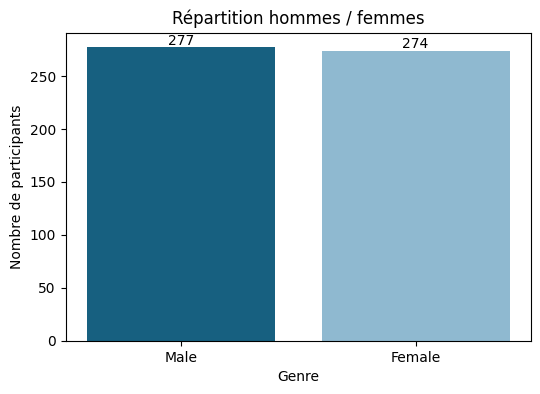

In [8]:
## Affichage du nombre de participants et de la répartition hommes/femmes

# Nombre de participants uniques

participants = df[['iid', 'Gender']].drop_duplicates()
print("Nombre total de participants :", participants['iid'].nunique())

# Répartition des genres

repartition_gender = participants['Gender'].value_counts()

# Visualisation 

plt.figure(figsize=(6,4))
plt.bar(repartition_gender.index, repartition_gender.values, color=['#176080', '#8FB9D0'])

plt.title("Répartition hommes / femmes")
plt.xlabel("Genre")
plt.ylabel("Nombre de participants")
for i, v in enumerate(repartition_gender.values):
    plt.text(i, v, str(v), ha='center', va='bottom')

plt.show()

,Valeurs manquantes,Pourcentage (%)
age,8,1.45


Statistiques descriptives :
     count   mean   std   min   25%   50%   75%   max
age  543.0  26.36  3.77  18.0  24.0  26.0  28.0  55.0


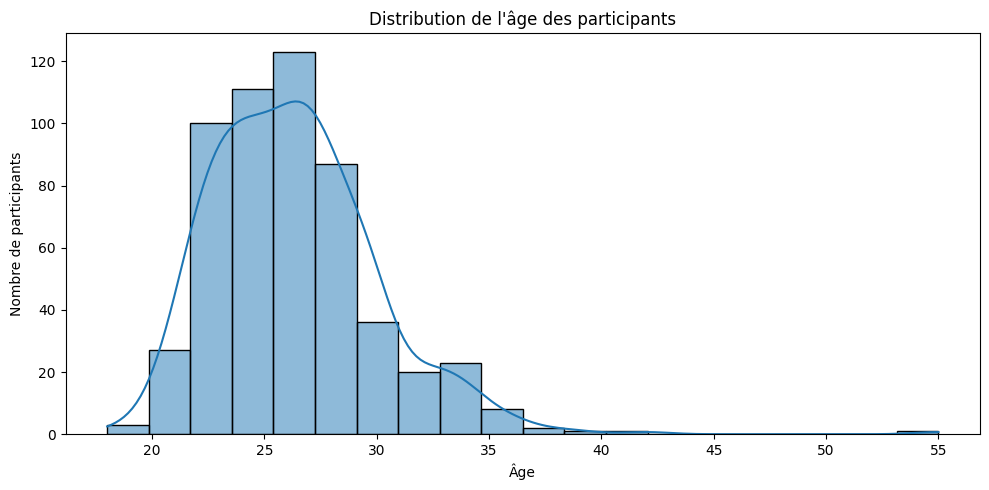

In [9]:
# Répartition de l'âge des participants

# Participants uniques
 
participants_age = df.drop_duplicates(subset='iid').copy()

# Vérification des valeurs manquantes au niveau des participants

missing = pd.DataFrame({
    'Valeurs manquantes': [participants_age['age'].isna().sum()],
    'Pourcentage (%)': [
        (participants_age['age'].isna().mean() * 100).round(2)
    ]
}, index=['age'])

display(missing)

# Statistiques descriptives

stats_age = participants_age['age'].describe().to_frame().T

print("Statistiques descriptives :")
print(stats_age.round(2))

# Visualisation

plt.figure(figsize=(10, 5))

sns.histplot(data=participants_age, x='age', bins=20, kde=True)

plt.title("Distribution de l'âge des participants")
plt.xlabel("Âge")
plt.ylabel("Nombre de participants")
plt.tight_layout()
plt.show()

,Valeurs manquantes,Pourcentage (%)
race,6,1.09


Répartition éthnique des participants :
race
European/Caucasion-American              304
Asian/Pacific_Islander/Asian-American    136
Latino/Hispanic_American                  42
Other                                     37
Black/African_American                    26
Name: count, dtype: int64


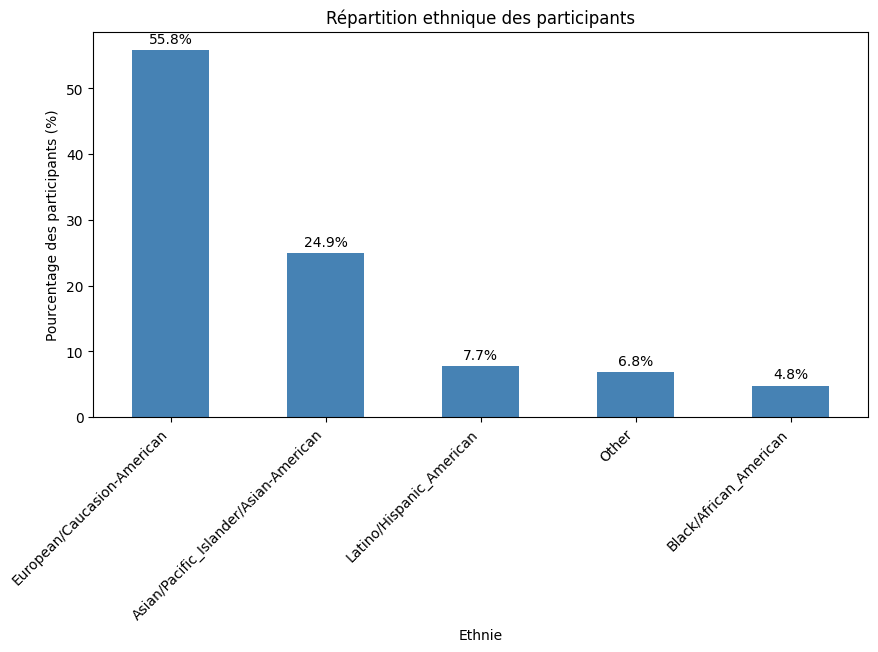

In [10]:
# Proportion de la répartition éthnique des participants 

# 1 ligne par participant

participants = df[['iid', 'race']].drop_duplicates()

# Vérification des valeurs manquantes au niveau des participants

missing = pd.DataFrame({
    'Valeurs manquantes': participants['race'].isna().sum(),
    'Pourcentage (%)': (
        participants['race'].isna().mean() * 100
    ).round(2)
}, index=['race'])

display(missing)

# Calcul des participants par ethnie

race = participants['race'].value_counts()

# Calcul des pourcentages

tableau_proportions_race = tableau_proportions_race = (
    race / race.sum() * 100
).round(2)

print("Répartition éthnique des participants :")
print(race)

# Visualisation

plt.figure(figsize=(10, 5))

ax = tableau_proportions_race.sort_values(ascending=False).plot(
    kind='bar',
    color='steelblue'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title("Répartition ethnique des participants")
plt.xlabel("Ethnie")
plt.ylabel("Pourcentage des participants (%)")
plt.xticks(rotation=45, ha='right')

plt.show()


Gender                                 Female  Male
race                                               
European/Caucasion-American               142   162
Asian/Pacific_Islander/Asian-American      71    65
Latino/Hispanic_American                   25    17
Other                                      16    21
Black/African_American                     16    10


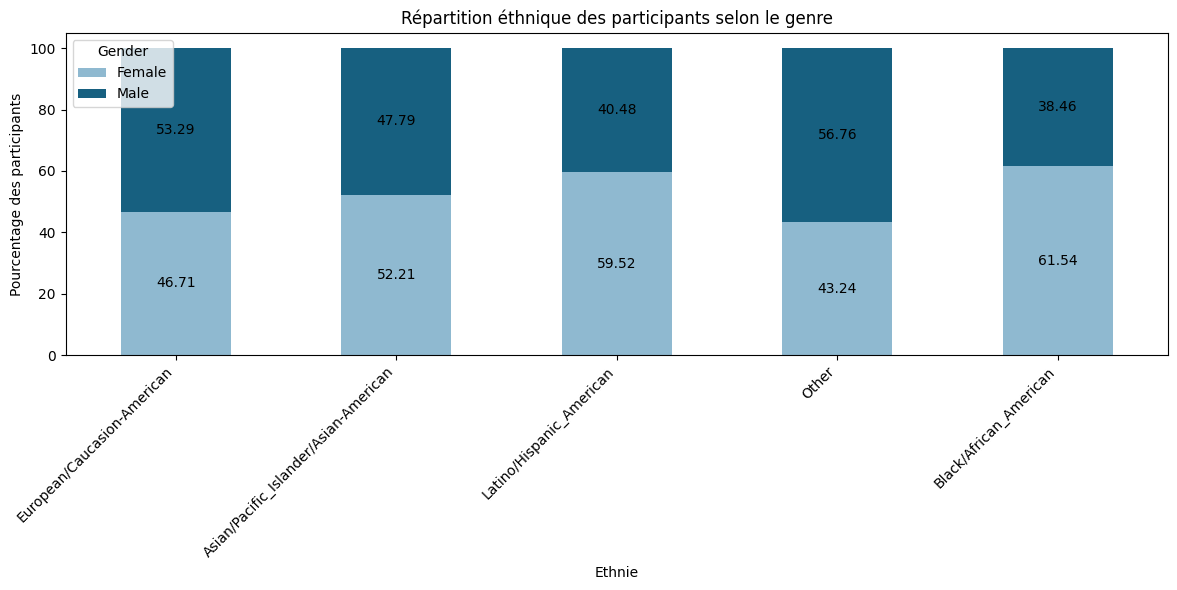

In [11]:
# Répartition éthnique des participants selon le genre

# 1 ligne par participant

participants = df[['iid', 'Gender', 'race']].drop_duplicates()

# Groupby sur participants

race = participants.groupby(['race', 'Gender']).size().unstack()

# Tri décroissant

race = race.loc[race.sum(axis=1).sort_values(ascending=False).index]
print(race)

# Création d'un graphique
# Les pourcentages par ethnie

race_pct = (race.div(race.sum(axis=1), axis=0) * 100).round(2)

# Graphique 

ax = race_pct.plot(kind='bar', stacked=True, figsize=(12,6), color=['#8FB9D0', '#176080'])

plt.title("Répartition éthnique des participants selon le genre")
plt.xlabel("Ethnie")
plt.ylabel("Pourcentage des participants")
plt.xticks(rotation=45, ha='right')

for container in ax.containers:
    ax.bar_label(container, label_type='center')

plt.legend(title="Gender")
plt.tight_layout()
plt.show()

,Valeurs manquantes,Pourcentage (%)
field_cd,7,1.27


Répartition des domaines d'études


,Effectif,Proportion (%)
field_cd,,
Business/Econ/Finance,130,23.90
Biological Sciences / Chemistry/ Physics,61,11.21
Engineering,56,10.29
Law,48,8.82
"Social Science, Psychologist",46,8.46
Political Science/ International Affairs,46,8.46
"Education, Academia",40,7.35
Social Work,30,5.51
English/Creative Writing / Journalism,21,3.86


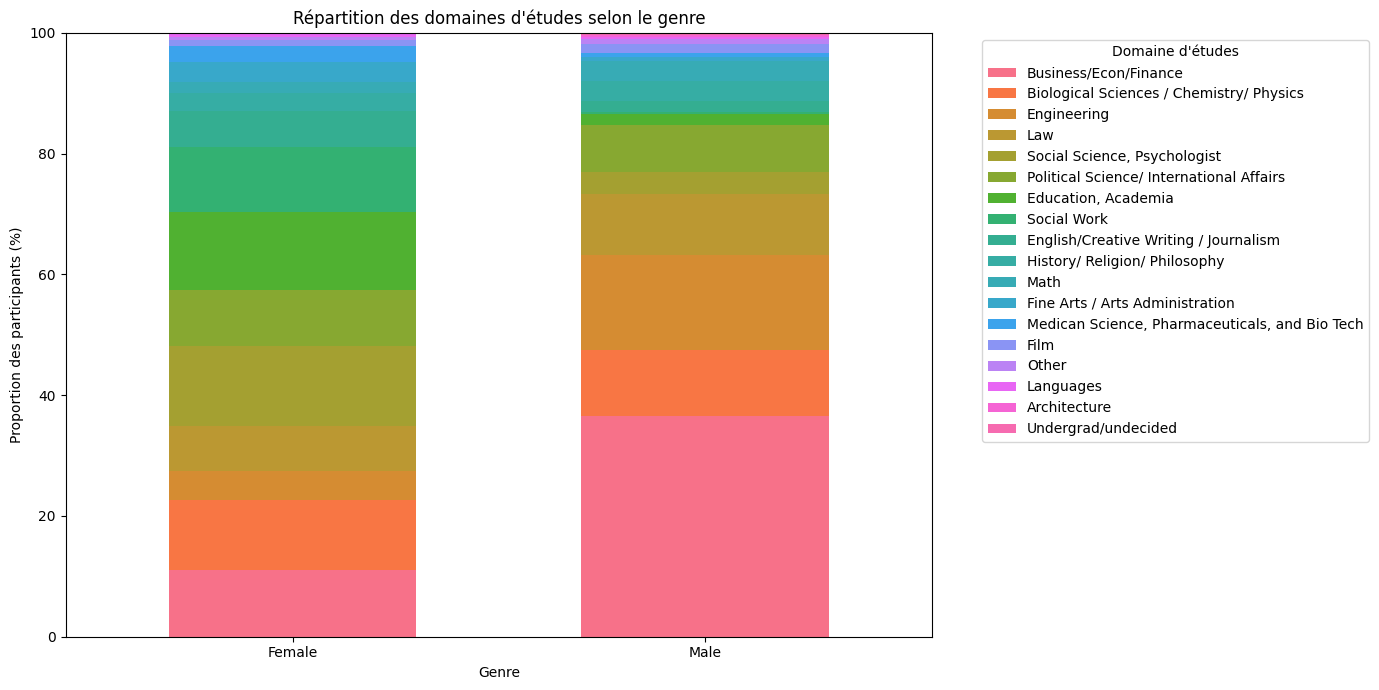

In [12]:
# Domaines d'études par participant

# Une ligne par participant

participants = df[['iid', 'Gender', 'field_cd']].drop_duplicates()

# Vérification des valeurs manquantes au niveau des participants

missing = pd.DataFrame({
    'Valeurs manquantes': participants['field_cd'].isna().sum(),
    'Pourcentage (%)': (
        participants['field_cd'].isna().mean() * 100
    ).round(2)
}, index=['field_cd'])

display(missing)

# Tableau global : effectifs et proportions par domaine d'études

tableau_global = (
    participants
    .groupby('field_cd')['iid']
    .nunique()
    .to_frame(name='Effectif')
)

tableau_global['Proportion (%)'] = (
    tableau_global['Effectif']
    / tableau_global['Effectif'].sum() * 100
)

tableau_global = tableau_global.sort_values(
    by='Effectif', ascending=False
)

tableau_global['Proportion (%)'] = tableau_global['Proportion (%)'].round(2)

print("Répartition des domaines d'études")
display(tableau_global)


# Effectifs par domaine d'études et par genre

education = (
    participants
    .groupby(['field_cd', 'Gender'])
    .size()
    .unstack(fill_value=0)
)

education = education.loc[
    education.sum(axis=1).sort_values(ascending=False).index
]

# Proportions au sein de chaque genre

education_pct = education.div(education.sum(axis=0), axis=1) * 100

# Une couleur distincte par domaine

n_categories = education_pct.shape[0]
colors = sns.color_palette("husl", n_categories).as_hex()

# Graphique empilé à 100 %

ax = education_pct.T.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7),
    color=colors,
    width=0.6
)

plt.title("Répartition des domaines d'études selon le genre")
plt.xlabel("Genre")
plt.ylabel("Proportion des participants (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.legend(
    title="Domaine d'études",
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

,Valeurs manquantes,Pourcentage (%)
career_c,12,2.18


Répartition des métiers envisagés


,Effectif,Proportion (%)
career_c,,
Academic / Research,152,28.20
Banking / Consulting /Finance / Marketing/ Business /CEO/ Entrepreneur / Admin,144,26.72
Lawyer,47,8.72
Creative Arts/ Entertainment,46,8.53
International /Humanitarian_Affairs,35,6.49
Doctor/Medicine,26,4.82
Undecided,25,4.64
Psychologist,17,3.15
Engineer,14,2.60


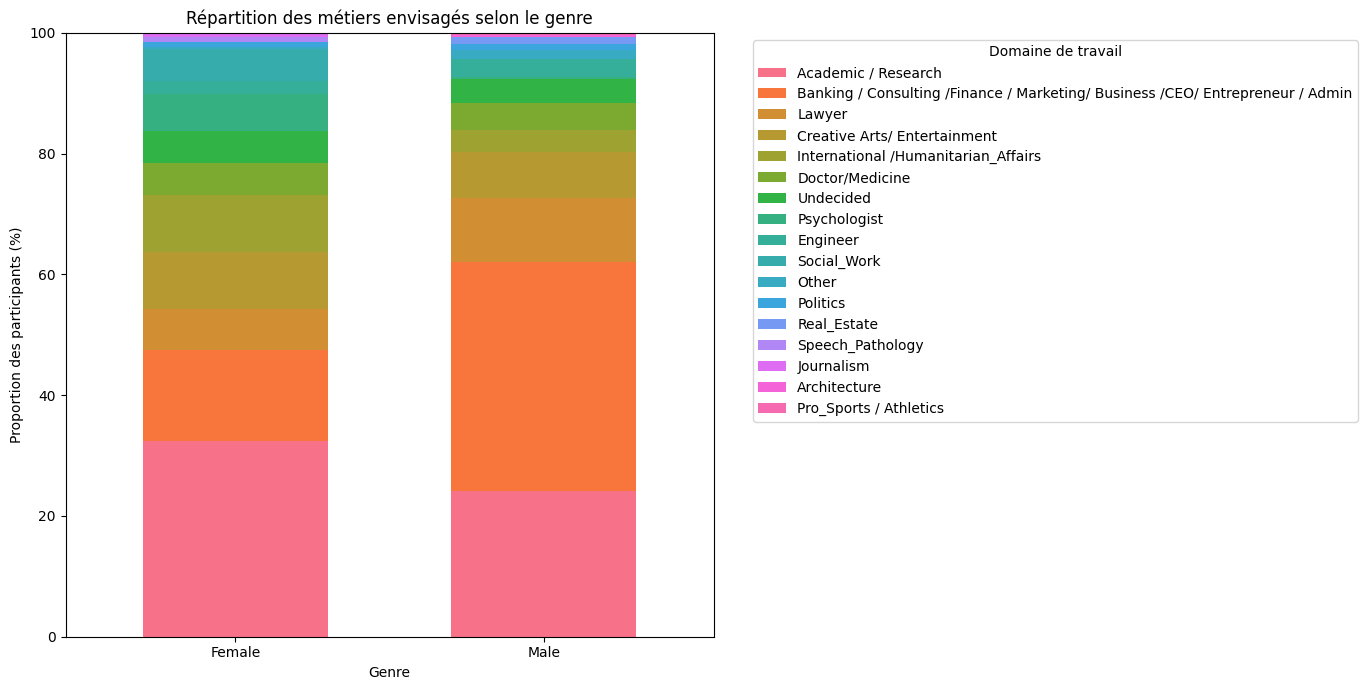

In [13]:
# Répartition des métiers envisagés par les participants

# Une ligne par participant

participants = df[['iid', 'Gender', 'career_c']].drop_duplicates()

# Vérification des valeurs manquantes au niveau des participants

missing = pd.DataFrame({
    'Valeurs manquantes': participants['career_c'].isna().sum(),
    'Pourcentage (%)': (
        participants['career_c'].isna().mean() * 100
    ).round(2)
}, index=['career_c'])

display(missing)

# Tableau global : effectifs et proportions par domaine

tableau_global = (
    participants
    .groupby('career_c')['iid']
    .nunique()
    .to_frame(name='Effectif')
)

tableau_global['Proportion (%)'] = (
    tableau_global['Effectif']
    / tableau_global['Effectif'].sum() * 100
)

tableau_global = tableau_global.sort_values(
    by='Effectif', ascending=False
)

tableau_global['Proportion (%)'] = tableau_global['Proportion (%)'].round(2)

print("Répartition des métiers envisagés")
display(tableau_global)


# Effectifs par domaine et par genre

career = (
    participants
    .groupby(['career_c', 'Gender'])
    .size()
    .unstack(fill_value=0)
)

# Tri décroissant selon l'effectif total

career = career.loc[
    career.sum(axis=1).sort_values(ascending=False).index
]

# Proportions au sein de chaque genre

career_pct = career.div(career.sum(axis=0), axis=1) * 100

# Une couleur distincte par domaine d'études

n_categories = career_pct.shape[0]
colors = sns.color_palette("husl", n_categories).as_hex()

# Graphique empilé à 100 %

ax = career_pct.T.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7),
    color=colors,
    width=0.6
)

plt.title("Répartition des métiers envisagés selon le genre")
plt.xlabel("Genre")
plt.ylabel("Proportion des participants (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.legend(
    title="Domaine de travail",
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

,Valeurs manquantes,Pourcentage (%)
goal,7,1.27


Répartition des objectifs


,Effectif,Proportion (%)
goal,,
Seemed_like_a_fun_night_out,228,41.38
To_meet_new_people,189,34.30
To_get_a_date,40,7.26
To_say_I_did_it,35,6.35
Other,30,5.44
Looking_for_serious_relationship,22,3.99
Objectif non renseigné,7,1.27


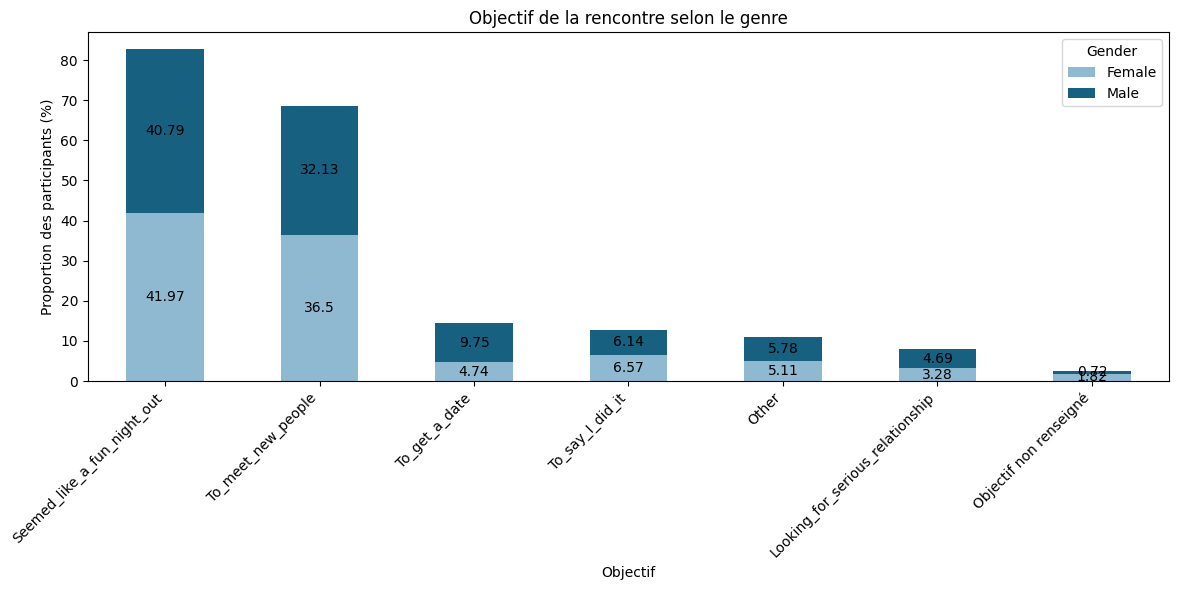

In [14]:
# Visualisation des objectifs des rencontres selon le genre

# Une ligne par participant

participants = df[['iid', 'Gender', 'goal']].drop_duplicates()

# Vérification des valeurs manquantes au niveau des participants

missing = pd.DataFrame({
    'Valeurs manquantes': participants['goal'].isna().sum(),
    'Pourcentage (%)': (
        participants['goal'].isna().mean() * 100
    ).round(2)
}, index=['goal'])
                       
display(missing)

# Remplacer le libellé des valeurs manquantes

participants['goal'] = participants['goal'].fillna(
    'Objectif non renseigné'
)

# Effectifs par objectif et par genre

goal = participants.groupby(['goal', 'Gender']).size().unstack(fill_value=0)

# Tri décroissant

goal = goal.loc[goal.sum(axis=1).sort_values(ascending=False).index]

# Tableau global : effectifs et proportions par goal

tableau_global = (
    participants
    .groupby('goal')['iid']
    .nunique()
    .to_frame(name='Effectif')
)

tableau_global['Proportion (%)'] = (
    tableau_global['Effectif']
    / tableau_global['Effectif'].sum() * 100
)

tableau_global = tableau_global.sort_values(
    by='Effectif', ascending=False
)

tableau_global['Proportion (%)'] = tableau_global['Proportion (%)'].round(2)

print("Répartition des objectifs")
display(tableau_global)

# Proportions au sein de chaque genre

objectif_pct = (goal.div(goal.sum(axis=0), axis=1) * 100).round(2)

# Création d'un graphique empilé

ax = objectif_pct.plot(kind='bar', stacked=True, figsize=(12,6), color=['#8FB9D0', '#176080'])

plt.title("Objectif de la rencontre selon le genre")
plt.xlabel("Objectif")
plt.ylabel("Proportion des participants (%)")
plt.xticks(rotation=45, ha='right')

for container in ax.containers:
    ax.bar_label(container, label_type='center')

plt.legend(title="Gender")
plt.tight_layout()
plt.show()

In [15]:
# Evaluation des critères selon le genre en fonction du type d'évaluation

attributes = ['attr1_1', 'sinc1_1', 'intel1_1', 'fun1_1', 'amb1_1', 'shar1_1']

# Une ligne par participant

participants = df[['iid', 'Gender', 'wave'] + attributes].drop_duplicates()

# Vérification des valeurs manquantes

missing = pd.DataFrame({
    'Valeurs manquantes': participants[attributes].isna().sum(),
    'Pourcentage (%)': (
        participants[attributes].isna().mean() * 100
    ).round(2)
})

display(missing)

# Répartition des méthodes de notation
## Les vagues de 1 à 5 et 10 à 21 notent sur 100 points
## Les vagues de 6 à 9 notent sur 10 points

points_method_1 = participants[
    participants['wave'].between(1, 5) |
    participants['wave'].between(10, 21)
]

points_method_2 = participants[
    participants['wave'].between(6, 9)
]

# Moyennes par genre, pour chaque méthode

mean_1 = points_method_1.groupby('Gender')[attributes].mean().round(2)
mean_2 = points_method_2.groupby('Gender')[attributes].mean().round(2)

print("--------------------------")
print("Evaluation sur 100 points")
print("--------------------------")
print(mean_1)
print("--------------------------")
print("Evaluation sur 10 points")
print("--------------------------")
print(mean_2)

,Valeurs manquantes,Pourcentage (%)
attr1_1,7,1.27
sinc1_1,7,1.27
intel1_1,7,1.27
fun1_1,8,1.45
amb1_1,9,1.63
shar1_1,10,1.81


--------------------------
Evaluation sur 100 points
--------------------------
        attr1_1  sinc1_1  intel1_1  fun1_1  amb1_1  shar1_1
Gender                                                     
Female    18.77    18.21     21.55   17.25   12.01    12.25
Male      29.45    16.09     19.41   17.46    7.83    10.27
--------------------------
Evaluation sur 10 points
--------------------------
        attr1_1  sinc1_1  intel1_1  fun1_1  amb1_1  shar1_1
Gender                                                     
Female    14.75    18.28     18.45   17.53   16.35    14.65
Male      17.59    17.67     19.29   18.21   13.14    14.09


In [16]:
# Vérification de la méthode d'évaluation sur 10 points

print(points_method_2[attributes].describe().T)

print("Valeurs minimales :")
print(points_method_2[attributes].min())

print("Valeurs maximales :")
print(points_method_2[attributes].max())

          count       mean       std    min    25%    50%    75%    max
attr1_1   101.0  16.188614  3.539942   6.67  14.55  16.00  18.18  27.78
sinc1_1   101.0  17.971287  2.739375   5.13  16.67  17.95  19.57  23.81
intel1_1  101.0  18.873762  1.996339  14.71  17.31  18.75  20.00  23.81
fun1_1    101.0  17.875941  2.361175  12.50  16.67  17.78  19.23  27.78
amb1_1    101.0  14.726238  4.130033   2.33  13.04  15.56  17.78  20.59
shar1_1   101.0  14.365941  3.894198   2.27  12.50  15.09  16.67  23.81
Valeurs minimales :
attr1_1      6.67
sinc1_1      5.13
intel1_1    14.71
fun1_1      12.50
amb1_1       2.33
shar1_1      2.27
dtype: float64
Valeurs maximales :
attr1_1     27.78
sinc1_1     23.81
intel1_1    23.81
fun1_1      27.78
amb1_1      20.59
shar1_1     23.81
dtype: float64


In [17]:
# Vérification de la méthode d'évaluation sur 100 points

print(points_method_1[attributes].describe().T)

print("Valeurs minimales :")
print(points_method_1[attributes].min())

print("Valeurs maximales :")
print(points_method_1[attributes].max())

          count       mean        std  min    25%    50%   75%    max
attr1_1   443.0  24.166704  13.857936  0.0  15.00  20.00  30.0  100.0
sinc1_1   443.0  17.135598   7.870302  0.0  10.00  19.00  20.0   60.0
intel1_1  443.0  20.466117   7.533931  0.0  17.00  20.00  25.0   50.0
fun1_1    442.0  17.354344   6.766943  0.0  12.25  18.09  20.0   50.0
amb1_1    441.0   9.908753   6.284687  0.0   5.00  10.00  15.0   53.0
shar1_1   440.0  11.250500   6.803424  0.0   5.00  10.00  15.0   30.0
Valeurs minimales :
attr1_1     0.0
sinc1_1     0.0
intel1_1    0.0
fun1_1      0.0
amb1_1      0.0
shar1_1     0.0
dtype: float64
Valeurs maximales :
attr1_1     100.0
sinc1_1      60.0
intel1_1     50.0
fun1_1       50.0
amb1_1       53.0
shar1_1      30.0
dtype: float64


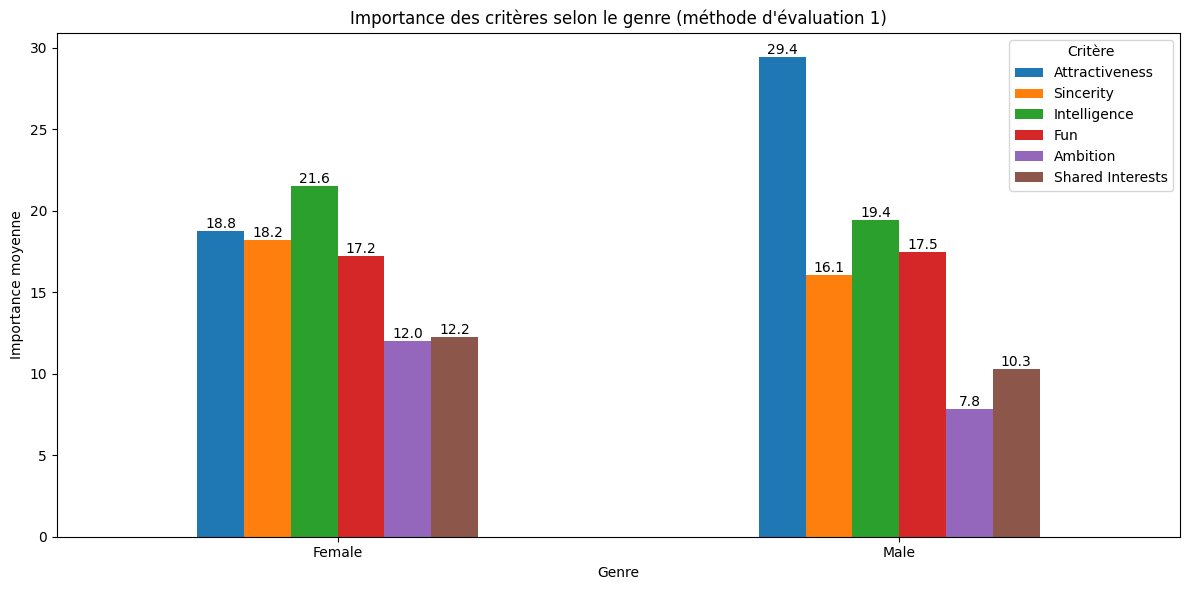

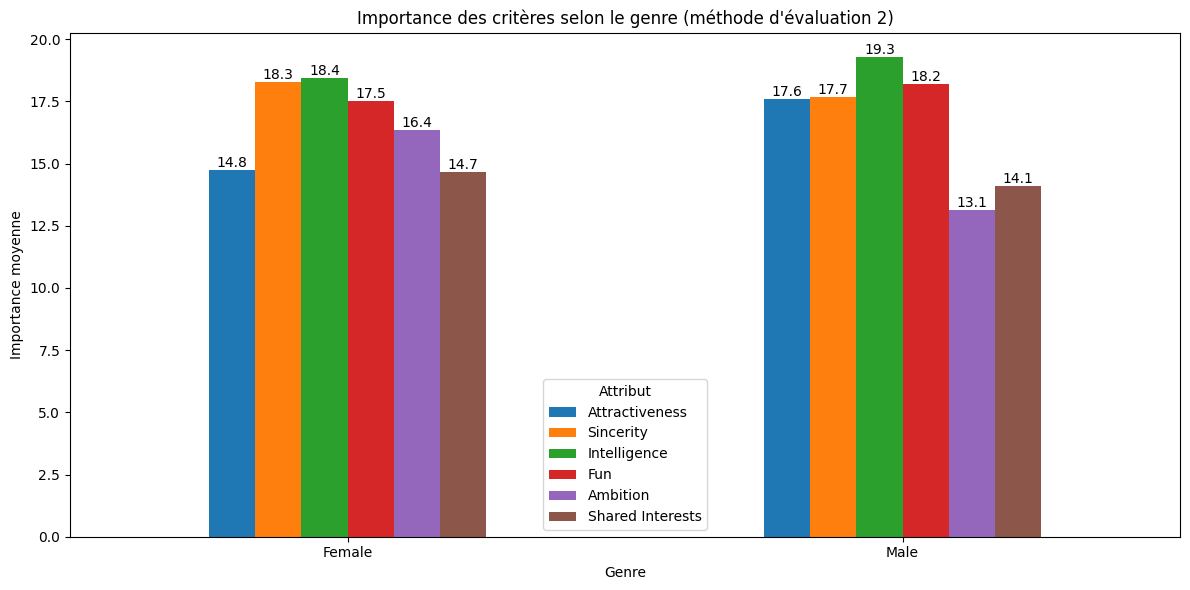

In [18]:
# Visualisation de l'importance des critères selon le genre avant les rencontres

# Noms des critères

labels = {
    'attr1_1': 'Attractiveness',
    'sinc1_1': 'Sincerity',
    'intel1_1': 'Intelligence',
    'fun1_1': 'Fun',
    'amb1_1': 'Ambition',
    'shar1_1': 'Shared Interests'
}

# Graphique 1 : évaluation sur 100 points

mean_1_plot = mean_1.rename(columns=labels)

ax = mean_1_plot.plot(kind='bar', figsize=(12,6))

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f')

plt.title("Importance des critères selon le genre (méthode d'évaluation 1)")
plt.xlabel("Genre")
plt.ylabel("Importance moyenne")
plt.xticks(rotation=0)

plt.legend(title="Critère")
plt.tight_layout()
plt.show()

# Graphique 2 : évaluation sur 10 points

mean_2_plot = mean_2.rename(columns=labels)

ax = mean_2_plot.plot(kind='bar', figsize=(12, 6))

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f')

plt.title("Importance des critères selon le genre (méthode d'évaluation 2)")
plt.xlabel("Genre")
plt.ylabel("Importance moyenne")
plt.xticks(rotation=0)

plt.legend(title="Attribut")
plt.tight_layout()
plt.show()


Valeurs manquantes parmi les participants


,Valeurs manquantes,Pourcentage (%)
race_importance,7,1.27
religion_importance,7,1.27


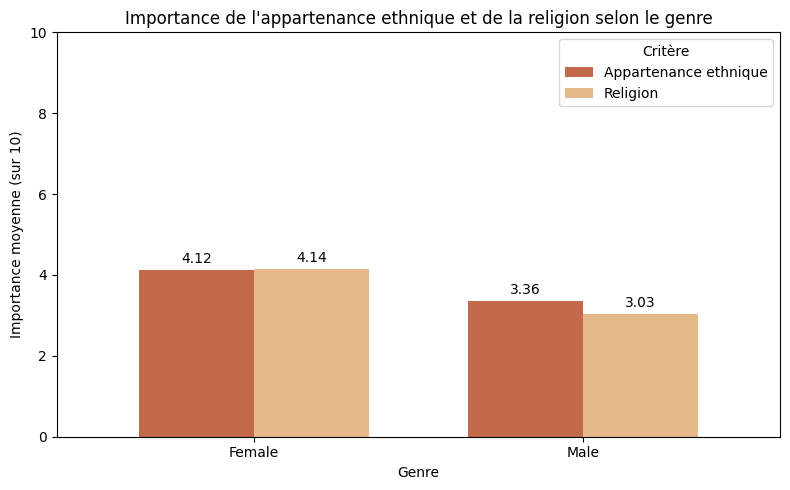

In [19]:
# Analyse de l'importance de la religion et de l'appartenance ethnique
# Échelle de notation de 1 à 10

variables = ['race_importance', 'religion_importance']

# Une ligne par participant

participants = (
    df[['iid', 'Gender'] + variables]
    .drop_duplicates(subset='iid')
)

# Valeurs manquantes au niveau des participants

missing = pd.DataFrame({
    'Valeurs manquantes': participants[variables].isna().sum(),
    'Pourcentage (%)': (
        participants[variables].isna().mean() * 100
    ).round(2)
})

print("Valeurs manquantes parmi les participants")
display(missing)

# Moyennes par genre,

importance = (
    participants
    .groupby('Gender')[variables]
    .mean()
    .rename(columns={
        'race_importance': 'Appartenance ethnique',
        'religion_importance': 'Religion'
    })
)

# Graphique

ax = importance.plot(
    kind='bar',
    figsize=(8, 5),
    width=0.7,
    color=['#C46A4A', '#E6B98A']
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.title(
    "Importance de l'appartenance ethnique et de la religion selon le genre"
)
plt.xlabel("Genre")
plt.ylabel("Importance moyenne (sur 10)")
plt.xticks(rotation=0)
plt.ylim(0, 10)
plt.legend(title="Critère")
plt.tight_layout()
plt.show()

### Profils des participants

L'analyse descriptive a permis de mieux comprendre le profil des participants avant d'étudier les facteurs associés à la réussite des rencontres.

Âge des participants

La population étudiée est principalement composée de jeunes adultes, âgés majoritairement de 23 à 29 ans, avec une concentration autour de 26–27 ans. La distribution est asymétrique vers la droite : la plupart des participants ont entre 20 et 30 ans, tandis qu'un nombre plus limité de personnes sont plus âgées.

Diversité ethnique

La population est majoritairement composée de participants se déclarant White/Caucasian-American, qui représentent 55,8 % de l'échantillon. Les participants Black/African-American représentent 24,9 %, tandis que les catégories Latino/Hispanic-American, Other et Asian/Pacific Islander-American sont moins représentées dans les proportions affichées. Cette répartition montre que l'échantillon présente une diversité ethnique, mais que les catégories ne sont pas représentées de manière équilibrée.

Domaines d'études et métiers envisagés

Les domaines d'études diffèrent selon le genre : les femmes sont davantage représentées dans plusieurs domaines liés aux sciences sociales, à la psychologie et aux sciences humaines, tandis que les hommes sont plus fortement représentés dans certains domaines scientifiques, techniques et économiques. Les métiers envisagés présentent également des différences : la recherche et le milieu universitaire occupent une place importante chez les femmes, tandis que les activités liées à la finance, au conseil et au monde des affaires sont particulièrement représentées chez les hommes.

Objectifs des rencontres

Les objectifs les plus fréquemment déclarés sont le fait de passer une soirée agréable et de rencontrer de nouvelles personnes. Ces deux motivations dominent chez les femmes comme chez les hommes. La recherche d'une relation sérieuse apparaît moins fréquemment, tout comme le souhait explicite d'obtenir un rendez-vous. Les objectifs semblent donc souvent associés à une démarche sociale et exploratoire plutôt qu'à la seule recherche d'une relation amoureuse sérieuse.

Critères de préférence

Les évaluations montrent que l'importance accordée aux critères varie selon le genre et selon la méthode de notation. Dans la première méthode, les femmes accordent la moyenne la plus élevée à l'intelligence (21,6), suivie de l'attractivité (18,8) et de la sincérité (18,2). Chez les hommes, l'attractivité arrive nettement en tête (29,4), devant l'intelligence (19,4) et l'humour (17,5). Dans la seconde méthode, l'intelligence obtient la moyenne la plus élevée pour les deux genres, avec 18,4 chez les femmes et 19,3 chez les hommes. Ces résultats suggèrent des différences dans les priorités déclarées, mais les deux méthodes de notation doivent être interprétées séparément, car leurs échelles et leurs vagues diffèrent.

Importance de l'appartenance ethnique et de la religion

Les moyennes sont relativement faibles sur une échelle de 10. Chez les femmes, l'importance moyenne de l'appartenance ethnique est de 4,12 et celle de la religion de 4,14. Chez les hommes, les moyennes sont respectivement de 3,36 et de 3,03. Dans cet échantillon, ces critères semblent donc recevoir une importance déclarée modérée, avec des moyennes plus élevées chez les femmes. Ces moyennes ne signifient toutefois pas que ces critères sont sans influence sur les décisions individuelles.

Bilan

Dans l'ensemble, les participants sont principalement de jeunes adultes, avec des profils d'études, des aspirations professionnelles et des préférences déclarées qui varient selon le genre. L'intelligence, l'attractivité, la sincérité et l'humour figurent parmi les critères importants, tandis que les objectifs déclarés sont souvent sociaux. Ces premières observations constituent une base descriptive pour la suite de l'étude.

## Analyse des matchs

#### Répartition des matches

In [20]:
# Regroupement des rencontres par participant

matches_par_personne = df.groupby('iid')['match'].apply(
    lambda x: (x == 'Yes').any()
)

# Calcul des résultats

nb_participants = len(matches_par_personne)
nb_avec_match = matches_par_personne.sum()
nb_sans_match = nb_participants - nb_avec_match

pourcentage_avec_match = nb_avec_match / nb_participants * 100
pourcentage_sans_match = nb_sans_match / nb_participants * 100

print("Nombre total de participants :", nb_participants)
print("Participants ayant eu au moins un match :", nb_avec_match)
print("Participants sans match :", nb_sans_match)
print(f"Pourcentage avec au moins un match : {pourcentage_avec_match:.2f} %")
print(f"Pourcentage sans match : {pourcentage_sans_match:.2f} %")


Nombre total de participants : 551
Participants ayant eu au moins un match : 452
Participants sans match : 99
Pourcentage avec au moins un match : 82.03 %
Pourcentage sans match : 17.97 %


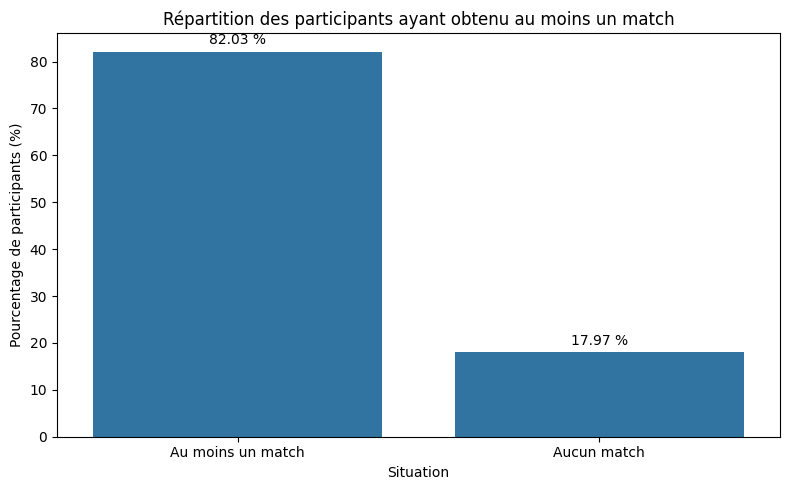

In [21]:
# Visualisation des pourcentages de participants

resultats = pd.Series({
    'Au moins un match': pourcentage_avec_match,
    'Aucun match': pourcentage_sans_match
}).round(2)

# Graphique

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=resultats.index, y=resultats.values)

plt.title("Répartition des participants ayant obtenu au moins un match")
plt.xlabel("Situation")
plt.ylabel("Pourcentage de participants (%)")

for i, valeur in enumerate(resultats.values):
    ax.text(i, valeur + 1, f'{valeur:.2f} %',
            ha='center', va='bottom')

plt.tight_layout()
plt.show()

#### Répartition des décisions positives

,Valeurs manquantes,Pourcentage (%)
dec,0,0.0


,nombre,taux_oui
order,,
1,551,49.91
2,551,39.38
3,551,42.11
4,551,44.65
5,551,42.29
6,541,44.18
7,514,41.63
8,508,40.94
9,502,44.42


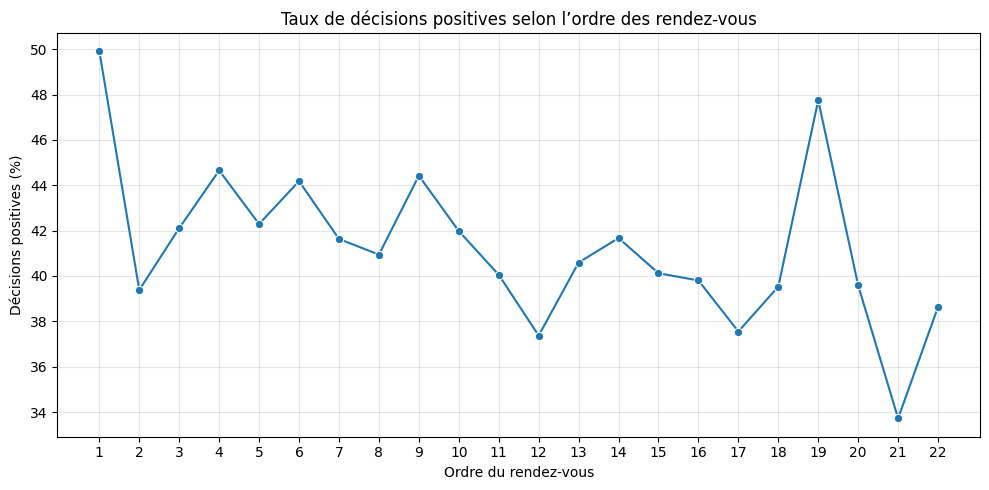

In [22]:
# Taux de décisions positives selon l'ordre des rendez-vous

# Vérification des valeurs manquantes dans ce sous-ensemble

missing_dec = pd.DataFrame(
    {
        'Valeurs manquantes': [df['dec'].isna().sum()],
        'Pourcentage (%)': [(df['dec'].isna().mean() * 100).round(2)]
    },
    index=['dec']
)

display(missing_dec)

# Taux de décision positives

resume_order = df.groupby('order')['dec'].agg(
    nombre='count',
    taux_oui='mean'
)

resume_order['taux_oui'] = (resume_order['taux_oui'] * 100).round(2)

display(resume_order)

# Graphique

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=resume_order.reset_index(),
    x='order',
    y='taux_oui',
    marker='o'
)

plt.title('Taux de décisions positives selon l’ordre des rendez-vous')
plt.xlabel('Ordre du rendez-vous')
plt.ylabel('Décisions positives (%)')
plt.xticks(sorted(df['order'].dropna().unique()))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### L'objectif du speed dating

,goal,Effectif,Participants_avec_match,taux_match
0,To_get_a_date,40,36,90.00
1,Looking_for_serious_relationship,22,19,86.36
2,Objectif non renseigné,7,6,85.71
3,Seemed_like_a_fun_night_out,228,192,84.21
4,To_meet_new_people,189,154,81.48
5,To_say_I_did_it,35,27,77.14
6,Other,30,18,60.00


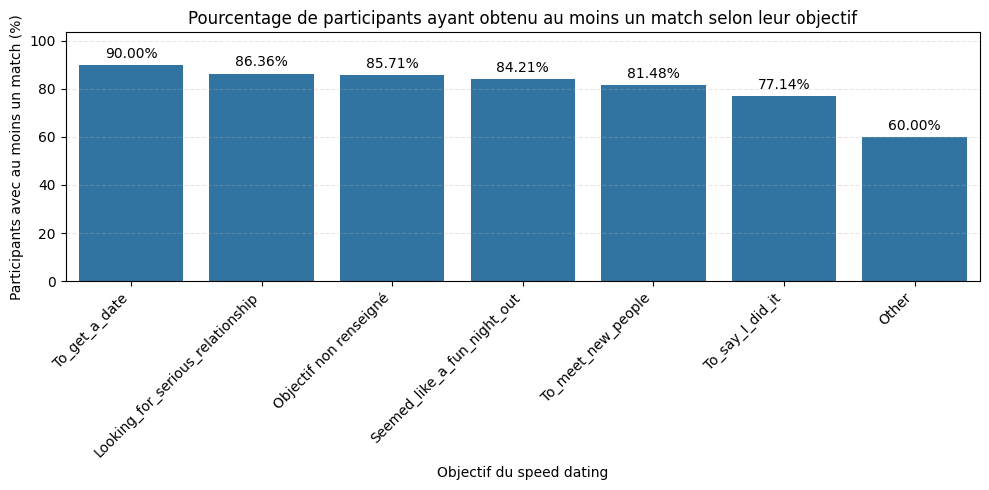

In [23]:
# Taux de participants ayant obtenu au moins un match,
# selon leur objectif de speed dating

participants_goal = df[['iid', 'goal', 'match']].copy()

# Remplacer le libellé des valeurs manquantes

participants_goal['goal'] = participants_goal['goal'].fillna(
    'Objectif non renseigné'
)

# Une ligne par participant et par objectif

participants_goal = participants_goal.groupby(
    ['iid', 'goal']
).agg(
    au_moins_un_match=('match', lambda x: (x == 'Yes').any())
).reset_index()

# Tableau : effectifs et taux de match par objectif

taux_match_goal = (
    participants_goal.groupby('goal')
    .agg(
        Effectif=('iid', 'nunique'),
        Participants_avec_match=('au_moins_un_match', 'sum'),
        taux_match=('au_moins_un_match', 'mean')
    )
    .reset_index()
)

# Conversion en pourcentage et tri décroissant

taux_match_goal['taux_match'] = (
    taux_match_goal['taux_match'] * 100
).round(2)

taux_match_goal = taux_match_goal.sort_values(
    by='taux_match', ascending=False
).reset_index(drop=True)

display(taux_match_goal)

# Visualisation

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=taux_match_goal,
    x='goal',
    y='taux_match'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

plt.title("Pourcentage de participants ayant obtenu au moins un match selon leur objectif")
plt.xlabel("Objectif du speed dating")
plt.ylabel("Participants avec au moins un match (%)")
plt.xticks(rotation=45, ha='right')
plt.ylim(0, taux_match_goal['taux_match'].max() * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
# Test du chi carré : existe-t-il une association entre l'objectif du speed dating et l'obtention d'au moins un match mutuel ?

# Une ligne par participant

participants = df.groupby('iid').agg(
    goal=('goal', 'first'),
    a_eu_match=('match', lambda x: (x == 'Yes').any())
).reset_index()

# Tableau croisé : objectif x au moins un match

table = pd.crosstab(
    participants['goal'],
    participants['a_eu_match']
)

display(table)

# Test du chi carré

chi2, p_value, dof, expected = chi2_contingency(table)

print(f"Statistique du chi carré : {chi2:.3f}")
print(f"Degrés de liberté : {dof}")
print(f"P-value : {p_value:.4f}")

# Vérification des effectifs théoriques

print(f"Effectif théorique minimum : {expected.min():.2f}")
print(
    f"Pourcentage d'effectifs théoriques inférieurs à 5 : "
    f"{(expected < 5).mean() * 100:.2f} %"
)

# Interprétation

if expected.min() < 1 or (expected < 5).mean() > 0.20:
    print("Attention : certains effectifs théoriques sont trop faibles. "
          "Le résultat doit être interprété avec prudence.")
elif p_value < 0.05:
    print("Résultat significatif : une association statistique est observée "
          "entre l'objectif et l'obtention d'au moins un match.")
else:
    print("Résultat non significatif : les données ne permettent pas "
          "de mettre en évidence une association statistiquement significative.")


a_eu_match,False,True
goal,,
Looking_for_serious_relationship,3,19
Other,12,18
Seemed_like_a_fun_night_out,36,192
To_get_a_date,4,36
To_meet_new_people,35,154
To_say_I_did_it,8,27


Statistique du chi carré : 13.196
Degrés de liberté : 5
P-value : 0.0216
Effectif théorique minimum : 3.96
Pourcentage d'effectifs théoriques inférieurs à 5 : 8.33 %
Résultat significatif : une association statistique est observée entre l'objectif et l'obtention d'au moins un match.


#### Appartenance éthnique

,samerace,nb_participants,participants_avec_match,taux_match,type_rencontre
0,No,551,350,63.52,Ethnies différentes
1,Yes,504,282,55.95,Même ethnie


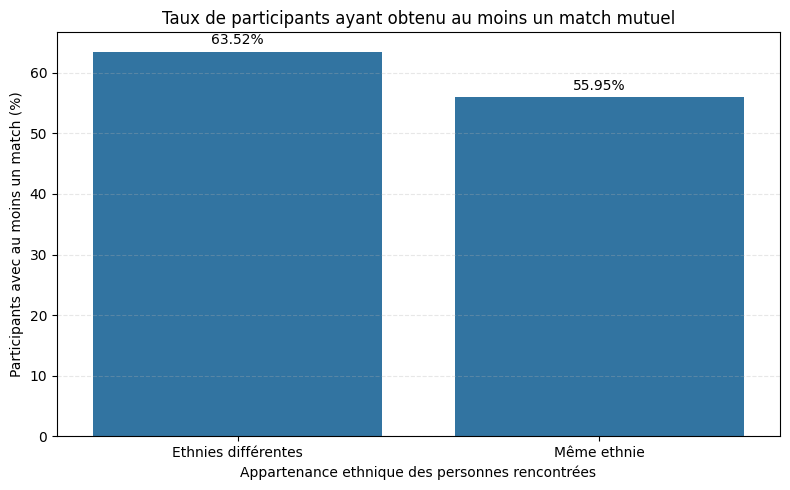

In [25]:
# Taux de participants ayant obtenu au moins un match mutuel
# selon l'appartenance ethnique des personnes rencontrées

# Une ligne par participant

participants_race = (
    df.dropna(subset=['samerace'])
    .groupby(['iid', 'samerace'])
    .agg(
        a_eu_match=('match', lambda x: (x == 'Yes').any())
    )
    .reset_index()
)

# Calcul des effectifs et des taux par type de rencontre

resultats_race = (
    participants_race.groupby('samerace')
    .agg(
        nb_participants=('iid', 'nunique'),
        participants_avec_match=('a_eu_match', 'sum'),
        taux_match=('a_eu_match', 'mean')
    )
    .reset_index()
)

# Pourcentage

resultats_race['taux_match'] = (
    resultats_race['taux_match'] * 100
).round(2)

# Renommer les catégories

resultats_race['type_rencontre'] = resultats_race['samerace'].map({
    'No': 'Ethnies différentes',
    'Yes': 'Même ethnie'
})

display(resultats_race)

# Visualisation

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=resultats_race,
    x='type_rencontre',
    y='taux_match',
    order=['Ethnies différentes', 'Même ethnie']
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

plt.title("Taux de participants ayant obtenu au moins un match mutuel")
plt.xlabel("Appartenance ethnique des personnes rencontrées")
plt.ylabel("Participants avec au moins un match (%)")
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

C:\Users\vavro\AppData\Local\Temp\ipykernel_31352\1879388406.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['match_num'] = (df['match'] == 'Yes').astype(int)


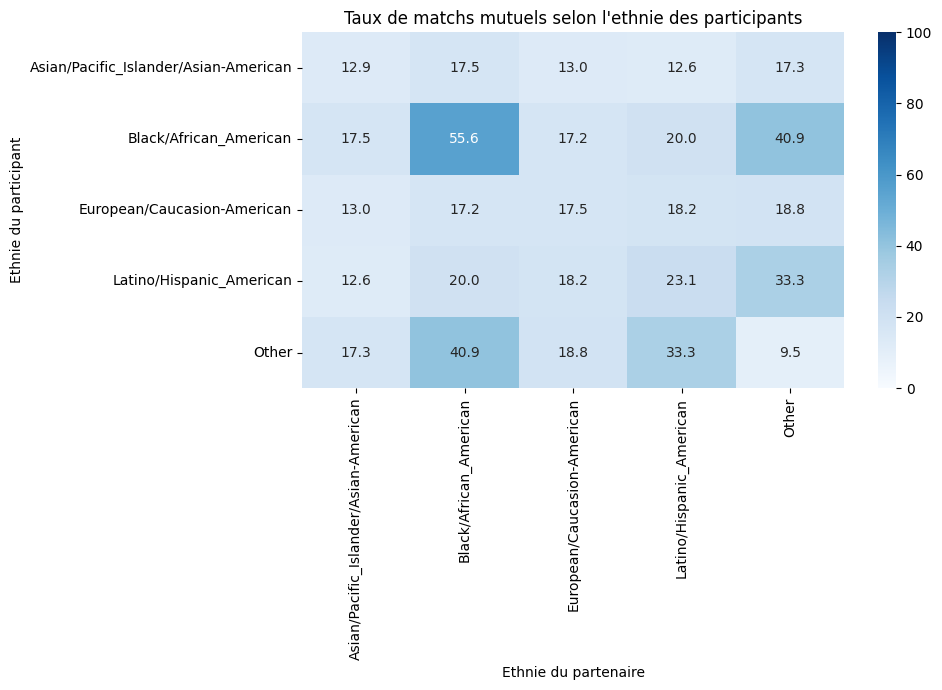

In [26]:
# Taux de matchs mutuels selon l'ethnie des deux participants

df['match_num'] = (df['match'] == 'Yes').astype(int)

taux_match = pd.pivot_table(
    df,
    values='match_num',
    index='race',
    columns='race_of_partner',
    aggfunc='mean'
) * 100

plt.figure(figsize=(10, 7))

sns.heatmap(
    taux_match,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100
)

plt.title("Taux de matchs mutuels selon l'ethnie des participants")
plt.xlabel("Ethnie du partenaire")
plt.ylabel("Ethnie du participant")

plt.tight_layout()
plt.show()

In [27]:
# Test statistique : les rencontres entre personnes de même origine ethnique aboutissent-elles plus souvent à un match mutuel ?

# Tableau croisé entre samerace et match

df_test = df.dropna(subset=['samerace', 'match'])

table_race = pd.crosstab(
    df_test['samerace'],
    df_test['match']
)

display(table_race)

# Test du chi carré
chi2, p_value, dof, expected = chi2_contingency(table_race)

print(f"Statistique du chi carré : {chi2:.3f}")
print(f"Degrés de liberté : {dof}")
print(f"P-value : {p_value:.4f}")
print(f"Effectif théorique minimum : {expected.min():.2f}")
print(
    f"Pourcentage d'effectifs théoriques inférieurs à 5 : "
    f"{(expected < 5).mean() * 100:.2f} %"
)

# Interprétation
if expected.min() < 1 or (expected < 5).mean() > 0.20:
    print("Attention : les effectifs théoriques sont faibles ; interpréter le test avec prudence.")
elif p_value < 0.05:
    print("Association statistiquement significative entre le fait d'être de la même ethnie et le match mutuel.")
else:
    print("Aucune association statistiquement significative n'est mise en évidence.")

match,No,Yes
samerace,,
No,4248,814
Yes,2750,566


Statistique du chi carré : 1.351
Degrés de liberté : 1
P-value : 0.2451
Effectif théorique minimum : 546.20
Pourcentage d'effectifs théoriques inférieurs à 5 : 0.00 %
Aucune association statistiquement significative n'est mise en évidence.


#### Age

count    1344.000000
mean        3.181548
std         2.669106
min         0.000000
25%         1.000000
50%         3.000000
75%         5.000000
max        17.000000
Name: ecart_age, dtype: float64


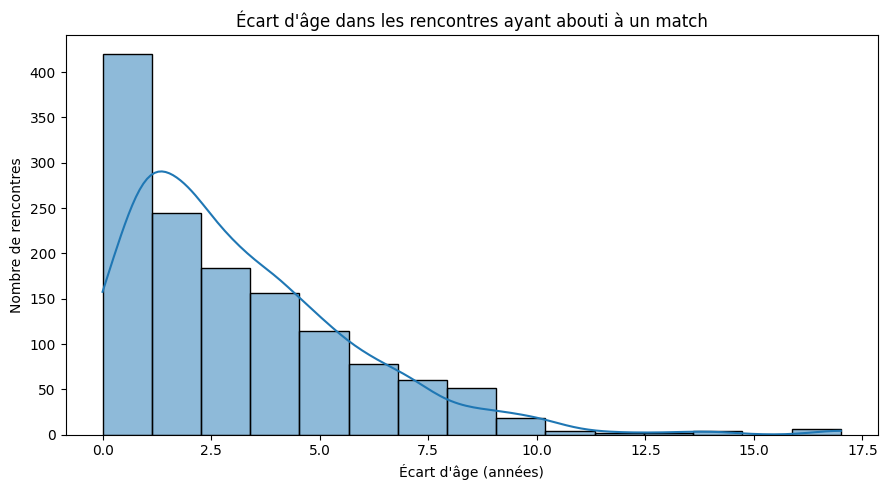

In [28]:
# Match vs. age

df_match = df[df['match'] == 'Yes'].copy()

df_match['ecart_age'] = (
    df_match['age'] - df_match['age_of_partner']
).abs()

df_match = df_match.dropna(subset=['ecart_age'])

print(df_match['ecart_age'].describe())

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_match,
    x='ecart_age',
    bins=15,
    kde=True
)

plt.title("Écart d'âge dans les rencontres ayant abouti à un match")
plt.xlabel("Écart d'âge (années)")
plt.ylabel("Nombre de rencontres")

plt.tight_layout()
plt.show()

,categorie_ecart,nb_rencontres,nb_matchs,taux_match
0,0–2 ans,3512,664,18.91
1,> 2–5 ans,2848,454,15.94
2,> 5–10 ans,1590,208,13.08
3,> 10 ans,230,18,7.83


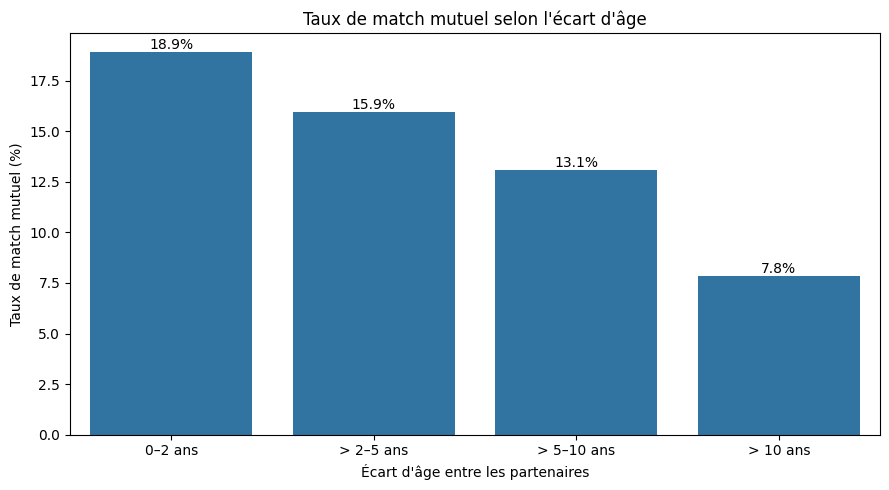

In [29]:

# L'importance de l'écart d'âge pour les matchs

df_age = df.dropna(subset=['age', 'age_of_partner', 'match']).copy()

df_age['match_num'] = (
    df_age['match'].astype(str).str.strip().str.lower() == 'yes'
).astype(int)

df_age['ecart_age'] = (
    df_age['age'] - df_age['age_of_partner']
).abs()

df_age['categorie_ecart'] = pd.cut(
    df_age['ecart_age'],
    bins=[-0.01, 2, 5, 10, float('inf')],
    labels=['0–2 ans', '> 2–5 ans', '> 5–10 ans', '> 10 ans']
)

resultats_age = (
    df_age.groupby('categorie_ecart', observed=False)
    .agg(
        nb_rencontres=('match_num', 'size'),
        nb_matchs=('match_num', 'sum'),
        taux_match=('match_num', 'mean')
    )
    .reset_index()
)

resultats_age['taux_match'] = (
    resultats_age['taux_match'] * 100
).round(2)

display(resultats_age)

# Visualisation
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=resultats_age,
    x='categorie_ecart',
    y='taux_match'
)

plt.title("Taux de match mutuel selon l'écart d'âge")
plt.xlabel("Écart d'âge entre les partenaires")
plt.ylabel("Taux de match mutuel (%)")

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%')

plt.tight_layout()
plt.show()


In [30]:
# Test statistique : l'écart d'âge entre les partenaires est-il associé à la probabilité d'un match mutuel ?

# Tableau croisé entre l'écart d'âge et le résultat de la rencontre

table_age = pd.crosstab(
    df_age['categorie_ecart'],
    df_age['match_num']
).reindex(columns=[0, 1], fill_value=0)

table_age.columns = ['Pas de match', 'Match']

display(table_age)

# Test du Chi-deux

chi2, p_value, dof, expected = chi2_contingency(table_age)

print(f"Statistique du Chi-deux : {chi2:.3f}")
print(f"Degrés de liberté : {dof}")
print(f"P-value : {p_value:.4f}")
print(f"Effectif théorique minimum : {expected.min():.2f}")
print(
    "Pourcentage d'effectifs théoriques inférieurs à 5 : "
    f"{(expected < 5).mean() * 100:.2f} %"
)

if expected.min() < 1 or (expected < 5).mean() > 0.20:
    print("Attention : les effectifs théoriques sont trop faibles pour une interprétation fiable du test.")
elif p_value < 0.05:
    print("Association statistiquement significative entre l'écart d'âge et le résultat de la rencontre.")
else:
    print("Aucune association statistiquement significative mise en évidence.")

,Pas de match,Match
categorie_ecart,,
0–2 ans,2848,664
> 2–5 ans,2394,454
> 5–10 ans,1382,208
> 10 ans,212,18


Statistique du Chi-deux : 41.566
Degrés de liberté : 3
P-value : 0.0000
Effectif théorique minimum : 37.79
Pourcentage d'effectifs théoriques inférieurs à 5 : 0.00 %
Association statistiquement significative entre l'écart d'âge et le résultat de la rencontre.


#### Activités

,Valeurs manquantes,Pourcentage (%)
sports,1,0.23
tvsports,1,0.23
exercise,1,0.23
dining,1,0.23
museums,1,0.23
art,1,0.23
hiking,1,0.23
gaming,1,0.23
clubbing,1,0.23
reading,1,0.23


Participants avec au moins une valeur manquante : 1
Participants avec toutes les activités manquantes : 1
Moyenne des notations des activités


,Femmes,Hommes
sports,5.80,7.22
tvsports,3.99,5.04
exercise,6.39,6.20
dining,8.24,7.45
museums,7.54,6.49
art,7.38,6.19
hiking,6.01,5.57
gaming,3.29,4.44
clubbing,6.09,5.68
reading,7.98,7.40


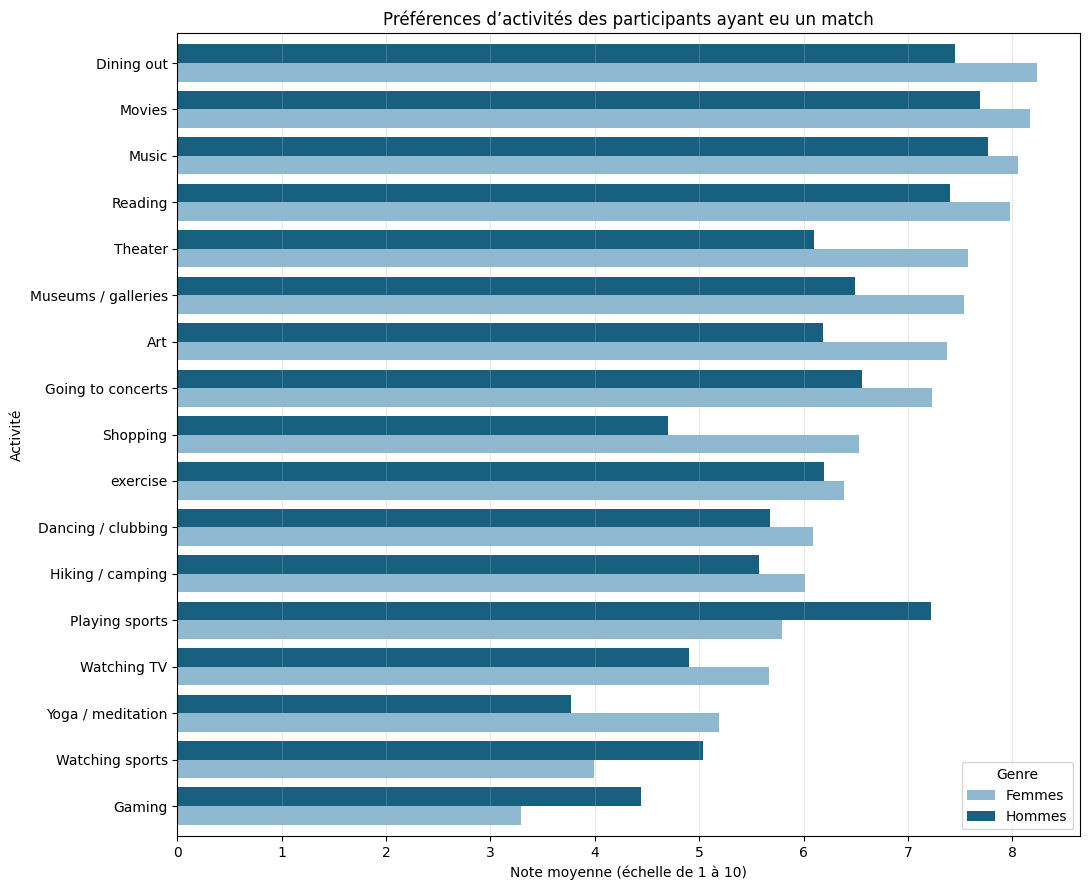

In [31]:
# Comparaison des préférences d'activités selon le genre

activities = [
    'sports', 'tvsports', 'exercise', 'dining',
    'museums', 'art', 'hiking', 'gaming', 'clubbing',
    'reading', 'tv', 'theater', 'movies', 'concerts',
    'music', 'shopping', 'yoga'
]

# Une ligne par participant ayant eu au moins un match

participants_activities = (
    df_match[['iid', 'Gender'] + activities]
    .drop_duplicates(subset='iid')
    .copy()
)

# Vérification des valeurs manquantes dans ce sous-ensemble

missing_activities = pd.DataFrame({
    'Valeurs manquantes': participants_activities[activities].isna().sum(),
    'Pourcentage (%)': (
        participants_activities[activities].isna().mean() * 100
    ).round(2)
})

display(missing_activities)

# Nombre de participants ayant au moins une activité manquante

print(
    "Participants avec au moins une valeur manquante :",
    participants_activities[activities].isna().any(axis=1).sum()
)

# Nombre de participants dont toutes les activités sont manquantes

print(
    "Participants avec toutes les activités manquantes :",
    participants_activities[activities].isna().all(axis=1).sum()
)

# Moyennes par genre

mean_activities = (
    participants_activities
    .groupby('Gender')[activities]
    .mean()
    .T
)

mean_activities.columns = ['Femmes', 'Hommes']

print("Moyenne des notations des activités")
display(mean_activities.round(2))

# Visualisation

labels_activities = {
    'sports': 'Playing sports',
    'tvsports': 'Watching sports',
    'excersice': 'Exercise / bodybuilding',
    'dining': 'Dining out',
    'museums': 'Museums / galleries',
    'art': 'Art',
    'hiking': 'Hiking / camping',
    'gaming': 'Gaming',
    'clubbing': 'Dancing / clubbing',
    'reading': 'Reading',
    'tv': 'Watching TV',
    'theater': 'Theater',
    'movies': 'Movies',
    'concerts': 'Going to concerts',
    'music': 'Music',
    'shopping': 'Shopping',
    'yoga': 'Yoga / meditation'
}

mean_activities = mean_activities.rename(index=labels_activities)

ax = mean_activities.sort_values('Femmes').plot(
    kind='barh',
    figsize=(11, 9),
    width=0.8,
    color=['#8FB9D0','#176080', ]
)

ax.set_title('Préférences d’activités des participants ayant eu un match')
ax.set_xlabel('Note moyenne (échelle de 1 à 10)')
ax.set_ylabel('Activité')
ax.legend(title='Genre')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()


In [32]:
# Comparaison des activités entres les couples ayant matché

activities = [
    'sports', 'tvsports', 'exercise', 'dining',
    'museums', 'art', 'hiking', 'gaming', 'clubbing',
    'reading', 'tv', 'theater', 'movies', 'concerts',
    'music', 'shopping', 'yoga'
]

# Une ligne par participant

participants = df[['iid', 'Gender'] + activities].drop_duplicates(subset='iid')

# Préférences du participant A

personne_A = participants.rename(columns={
    'iid': 'iid_A',
    'Gender': 'Gender_A',
    **{col: f'{col}_A' for col in activities}
})

# Préférences du participant B

personne_B = participants.rename(columns={
    'iid': 'iid_B',
    'Gender': 'Gender_B',
    **{col: f'{col}_B' for col in activities}
})

# Rencontres ayant abouti à un match

rencontres = df[df['match'] == 'Yes'][['iid', 'pid']].drop_duplicates()

# Relier chaque rencontre aux préférences des deux personnes

matches_activites = (
    rencontres
    .merge(personne_A, left_on='iid', right_on='iid_A')
    .merge(personne_B, left_on='pid', right_on='iid_B')
)

print("Préférences des participants :")
display(matches_activites.head())

# Calcul des écarts absolus pour chaque activité

for col in activities:
    matches_activites[f'ecart_{col}'] = (
        matches_activites[f'{col}_A'] -
        matches_activites[f'{col}_B']
    ).abs()
    
# Calcul de l'écart moyen par activité

ecarts = [f'ecart_{col}' for col in activities]

moyennes_ecarts = (
    matches_activites[ecarts]
    .mean()
    .rename(lambda col: col.replace('ecart_', ''))
    .sort_values(ascending=True)
)

print("Ecart moyen par activité :")
display(moyennes_ecarts.round(2))

Préférences des participants :


,iid,pid,iid_A,Gender_A,sports_A,tvsports_A,exercise_A,dining_A,museums_A,art_A,...,gaming_B,clubbing_B,reading_B,tv_B,theater_B,movies_B,concerts_B,music_B,shopping_B,yoga_B
0,1,13.0,1,Female,9.0,2.0,8.0,9.0,1.0,1.0,...,7.0,7.0,6.0,8.0,10.0,8.0,9.0,9.0,8.0,1.0
1,1,14.0,1,Female,9.0,2.0,8.0,9.0,1.0,1.0,...,8.0,8.0,6.0,7.0,3.0,10.0,6.0,8.0,6.0,1.0
2,1,15.0,1,Female,9.0,2.0,8.0,9.0,1.0,1.0,...,7.0,9.0,8.0,6.0,9.0,9.0,6.0,7.0,2.0,1.0
3,1,19.0,1,Female,9.0,2.0,8.0,9.0,1.0,1.0,...,7.0,9.0,8.0,1.0,1.0,7.0,7.0,7.0,7.0,10.0
4,2,14.0,2,Female,3.0,2.0,7.0,10.0,8.0,6.0,...,8.0,8.0,6.0,7.0,3.0,10.0,6.0,8.0,6.0,1.0


Ecart moyen par activité :


dining      1.88
reading     1.94
movies      1.95
music       1.99
museums     2.42
concerts    2.43
clubbing    2.61
art         2.64
exercise    2.68
theater     2.73
tv          2.84
hiking      2.89
gaming      3.03
sports      3.07
shopping    3.15
yoga        3.16
tvsports    3.16
dtype: float64

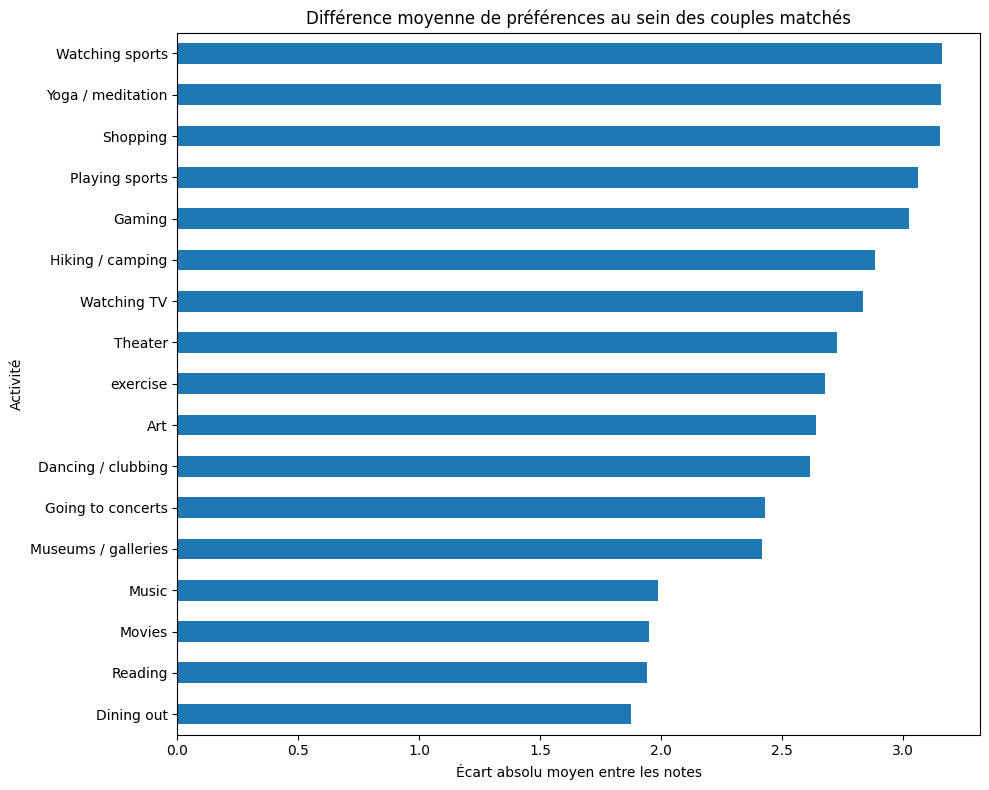

In [33]:
# Visualisation des écarts moyens

labels_activities = {
    'sports': 'Playing sports',
    'tvsports': 'Watching sports',
    'excersice': 'Exercise / bodybuilding',
    'dining': 'Dining out',
    'museums': 'Museums / galleries',
    'art': 'Art',
    'hiking': 'Hiking / camping',
    'gaming': 'Gaming',
    'clubbing': 'Dancing / clubbing',
    'reading': 'Reading',
    'tv': 'Watching TV',
    'theater': 'Theater',
    'movies': 'Movies',
    'concerts': 'Going to concerts',
    'music': 'Music',
    'shopping': 'Shopping',
    'yoga': 'Yoga / meditation'
}

moyennes_ecarts = moyennes_ecarts.rename(index=labels_activities)

ax = moyennes_ecarts.sort_values().plot(
    kind='barh',
    figsize=(10, 8)
)

ax.set_title('Différence moyenne de préférences au sein des couples matchés')
ax.set_xlabel('Écart absolu moyen entre les notes')
ax.set_ylabel('Activité')

plt.tight_layout()
plt.show()

In [34]:
# Test statistique : Existe-t-il une association significative entre la similarité des préférences 
# en matière d’activités et la probabilité de former un match lors d’un speed dating ?


# Récupérer toutes les rencontres, avec et sans match

rencontres = df[['iid', 'pid', 'match']].dropna(
    subset=['iid', 'pid', 'match']
).copy()

# Éviter de compter deux fois la même paire

rencontres['id_min'] = rencontres[['iid', 'pid']].min(axis=1)
rencontres['id_max'] = rencontres[['iid', 'pid']].max(axis=1)

rencontres = rencontres.drop_duplicates(
    subset=['id_min', 'id_max']
)

# Créer une variable numérique pour le match

rencontres['match_num'] = (
    rencontres['match'].astype(str).str.strip().str.lower() == 'yes'
).astype(int)

# Relier chaque rencontre aux préférences des deux participants

comparaison = (
    rencontres
    .merge(personne_A, left_on='iid', right_on='iid_A')
    .merge(personne_B, left_on='pid', right_on='iid_B')
)

# Calculer l'écart absolu pour chaque activité

for col in activities:
    comparaison[f'ecart_{col}'] = (
        comparaison[f'{col}_A'] - comparaison[f'{col}_B']
    ).abs()

# Écart moyen entre les préférences des deux personnes,
# calculé pour chaque rencontre

colonnes_ecarts = [f'ecart_{col}' for col in activities]

comparaison['ecart_moyen'] = comparaison[colonnes_ecarts].mean(axis=1)

# Séparer les rencontres avec et sans match

ecarts_match = comparaison.loc[
    comparaison['match_num'] == 1, 'ecart_moyen'
].dropna()

ecarts_sans_match = comparaison.loc[
    comparaison['match_num'] == 0, 'ecart_moyen'
].dropna()

# Afficher les effectifs et les écarts moyens

print("Nombre de rencontres avec match :", len(ecarts_match))
print("Nombre de rencontres sans match :", len(ecarts_sans_match))

print("Écart moyen avec match :", round(ecarts_match.mean(), 2))
print("Écart moyen sans match :", round(ecarts_sans_match.mean(), 2))

# Test de Mann–Whitney

statistique, p_value = mannwhitneyu(
    ecarts_match,
    ecarts_sans_match,
    alternative='two-sided'
)

print("Statistique de Mann–Whitney :", round(statistique, 3))
print("p-value :", round(p_value, 4))

if p_value < 0.05:
    print("\nConclusion : la différence est statistiquement significative (p < 0,05).")
    if ecarts_match.mean() < ecarts_sans_match.mean():
        print("Les couples matchés ont des préférences globalement plus similaires.")
    else:
        print("Les couples matchés ont des préférences globalement moins similaires.")
else:
    print("\nConclusion : aucune différence statistiquement significative n'est mise en évidence (p ≥ 0,05).")

Nombre de rencontres avec match : 675
Nombre de rencontres sans match : 3430
Écart moyen avec match : 2.62
Écart moyen sans match : 2.66
Statistique de Mann–Whitney : 1105945.5
p-value : 0.0662

Conclusion : aucune différence statistiquement significative n'est mise en évidence (p ≥ 0,05).


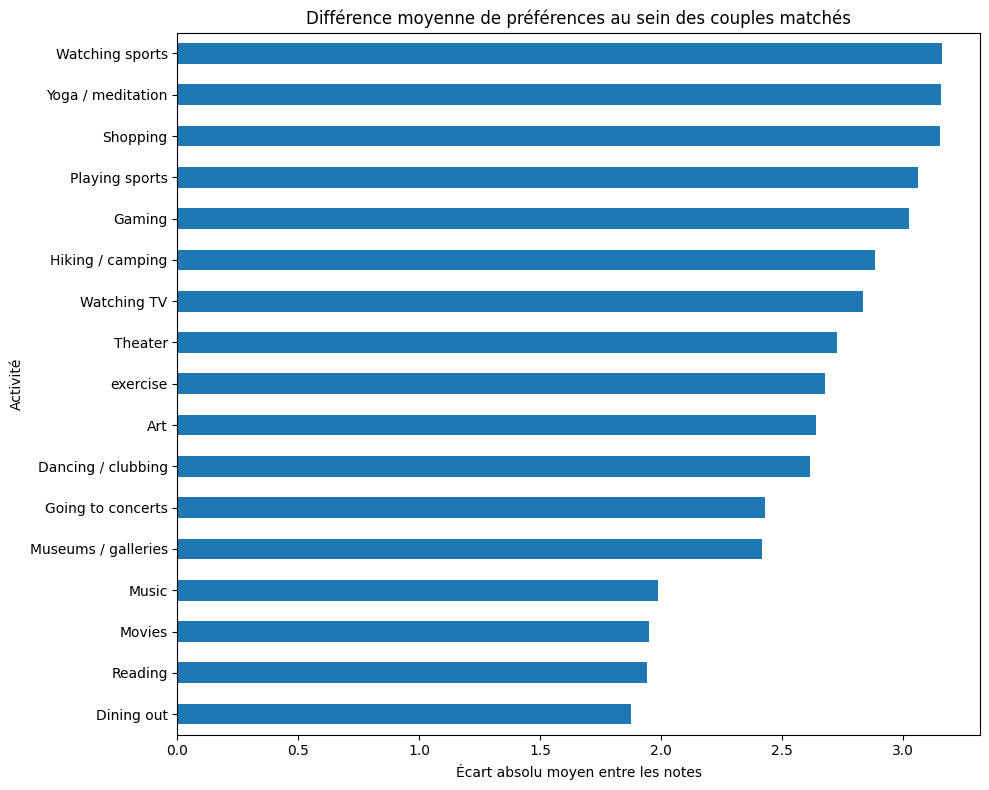

In [35]:
# Visualisation des écarts moyens

labels_activities = {
    'sports': 'Playing sports',
    'tvsports': 'Watching sports',
    'excersice': 'Exercise / bodybuilding',
    'dining': 'Dining out',
    'museums': 'Museums / galleries',
    'art': 'Art',
    'hiking': 'Hiking / camping',
    'gaming': 'Gaming',
    'clubbing': 'Dancing / clubbing',
    'reading': 'Reading',
    'tv': 'Watching TV',
    'theater': 'Theater',
    'movies': 'Movies',
    'concerts': 'Going to concerts',
    'music': 'Music',
    'shopping': 'Shopping',
    'yoga': 'Yoga / meditation'
}

moyennes_ecarts = moyennes_ecarts.rename(index=labels_activities)

ax = moyennes_ecarts.sort_values().plot(
    kind='barh',
    figsize=(10, 8)
)

ax.set_title('Différence moyenne de préférences au sein des couples matchés')
ax.set_xlabel('Écart absolu moyen entre les notes')
ax.set_ylabel('Activité')

plt.tight_layout()
plt.show()

### Conclusion - Analyse des matches en speed dating

L’analyse des données de speed dating met en évidence plusieurs facteurs associés à l’obtention d’un match, mais tous ne présentent pas le même niveau d’association statistique.

Matchs 

Sur les 551 participants étudiés, 452 ont obtenu au moins un match, soit 82,03 %, tandis que 99 participants n’ont obtenu aucun match, soit 17,97 %. Les résultats montrent que le taux de décisions positives varie selon l’ordre des rendez-vous, mais sans suivre une tendance régulière. Il est le plus élevé lors du premier rendez-vous (49,91 %), puis diminue à 39,38 % au deuxième. Les décisions positives semblent plus fréquentes au début de la session, notamment lors du premier rendez-vous, mais les variations observées ne permettent pas d’affirmer que les participants deviennent systématiquement plus ou moins enclins à répondre positivement au fil des rencontres.

Objectifs du speed dating

Les résultats montrent que le taux d’obtention d’au moins un match varie selon l’objectif déclaré par les participants. Les personnes souhaitant trouver un rendez-vous présentent le taux le plus élevé, avec 90 %, suivies de celles recherchant une relation sérieuse (86,36 %). Le test du chi carré indique une association statistiquement significative entre l’objectif déclaré et l’obtention d’au moins un match. Cependant, ces résultats doivent être interprétés avec prudence : certains groupes sont de petite taille.

Appartenance éthnique

Les résultats descriptifs montrent que le taux d’obtention d’au moins un match est de 63,52 % lorsque les participants rencontrent une personne d’une ethnie différente, contre 55,95 % lorsqu’ils rencontrent une personne de la même ethnie. Cependant, le test du chi carré ne met pas en évidence d’association statistiquement significative entre les deux variables, car la p-value est supérieure au seuil de 0,05. La heatmap met en évidence des différences de taux de match selon les combinaisons d’appartenances ethniques. Le taux le plus élevé parmi les exemples relevés concerne les rencontres entre deux personnes s’identifiant comme Black/African American, avec 55,6 % de matchs.

Age

Les résultats montrent que le taux de match diminue progressivement à mesure que l’écart d’âge entre les deux participants augmente. Il 
atteint 18,91 % lorsque l’écart est compris entre 0 et 2 ans, contre 15,94 % pour un écart supérieur à 2 ans et allant jusqu’à 5 ans, puis 13,08 % pour un écart supérieur à 5 ans et allant jusqu’à 10 ans. Enfin, lorsque l’écart dépasse 10 ans, le taux de match tombe à 7,83 %. Le test du chi carré confirme l’existence d’une association statistiquement significative entre la catégorie d’écart d’âge et le résultat de la rencontre.

Activités 

Les résultats montrent que les femmes et les hommes n’accordent pas exactement la même importance aux différentes activités. Parmi les couples ayant matché, les écarts moyens de préférences les plus faibles concernent les sorties au restaurant (1,88), la lecture (1,94), les films (1,95) et la musique (1,99). Les écarts les plus élevés sont observés pour le yoga (3,16), les sports télévisés (3,16) et le shopping (3,15). Ces résultats suggèrent que les goûts communs dans certains domaines pourraient accompagner la formation d’un match. Concernant le test statistique, l’écart moyen entre les préférences des participants est légèrement plus faible pour les rencontres ayant abouti à un match (2,62) que pour celles sans match (2,66). Cette différence reste toutefois très faible. Le test de Mann–Whitney donne une p-value de 0,0662, supérieure au seuil de significativité de 0,05. Il ne met donc pas en évidence de différence statistiquement significative entre les distributions des écarts de préférences des deux groupes.

En définitive, l’objectif déclaré et la proximité d’âge sont les deux facteurs étudiés qui présentent une association statistiquement significative avec l’obtention d’un match. En revanche, les résultats ne permettent pas de mettre en évidence une association significative pour l’appartenance ethnique ou la similarité des préférences en matière d’activités. Ces conclusions restent limitées aux variables et aux analyses réalisées : elles décrivent des associations et ne démontrent pas de relations de cause à effet.